In [1]:
type Not[P] = P => Nothing

defined type Not

# Deaño

**** 2. $ \{ p \rightarrow q, r \vee s, s \rightarrow \neg q, \neg r \} \vdash \neg p $

In [2]:
def proof[P, Q, R, S](p1: P => Q, 
                      p2: Either[R, S], 
                      p3: S => Not[Q], 
                      p4: Not[R]): Not[P] = 
    p => p2 match {
        case Left(r) => p4(r): Nothing
        case Right(s) => p3(s)(p1(p))
    }

defined function proof

**** 4. $\{ p \rightarrow (q \vee r), \neg r, q \rightarrow (s \vee t), \neg (s \vee t)\} \vdash \neg p $

In [3]:
def proof[P, Q, R, S, T](p1: P => Either[Q, R], 
                         p2: Not[R], 
                         p3: Q => Either[S, T], 
                         p4: Not[Either[S, T]]): 
                             Not[P] = 
     (p: P) => 
        p2(p1(p) match {
            case Left(q) => p4(p3(q))
            case Right(r) => r
        })

defined function proof

5. 

In [4]:
def proof[P, Q, R, S](p1: R => S, p2: Either[P, Q], p3: Not[Not[P] => S]): (Q, Not[R]) = 
    p2 match {
        case Left(p) => 
            (p3(np => np(p)), 
             r => p3(np => np(p)))
        case Right(q) => 
            (q, 
             r => p3(_ => p1(r)))
    }

defined function proof

44. $ \{ (p \wedge q) \rightarrow (r \vee s), \neg(t\wedge \neg p ),\; t,\; t \rightarrow q, q \rightarrow t\} \vdash \neg r \rightarrow s$

In [5]:
def proof[P, Q, R, S, T](lem: Either[P, Not[P]])(
                         p1: (P, Q) => Either[R, S], 
                         p2: Not[(T, Not[P])], 
                         p3: T, 
                         p4: T => Q, 
                         p5: Q => T): 
                             Not[R] => S = 
    (nr: Not[R]) => lem match {
        case Left(p) => p1(p, p4(p3)) match {
            case Left(r) => nr(r)
            case Right(s) => s
        }
        case Right(np) => p2((p3, np))
    }

defined function proof

# LEM, DN, ... 

$⊢ \neg \neg (p \vee \neg p) $

In [6]:
def proof[P]: Not[Not[Either[P, Not[P]]]] = 
    (notPorNotP: Either[P, Not[P]] => Nothing) => 
        notPorNotP(Right((p: P) => 
                             notPorNotP(Left(p)) : Nothing
                        ): Either[P, Not[P]]
                  ): Nothing

defined function proof

In [7]:
def proofC[P](emp: P Either Not[P]): Not[Not[P]] => P = 
    nnp => emp match {
        case Left(p) => p
        case Right(np) => nnp(np)
    }

defined function proofC

(P ⇒ Q) ∨ (Q ⇒ R) linearity principle

$ (p \rightarrow q) \vee (q \rightarrow r) $ 

In [8]:
def proof[P, Q, R](lemq: Either[Q, Not[Q]]): Either[P => Q, Q => R] = 
    lemq match {
        case Left(q) => 
            Left(p => q)
        case Right(nq) => 
            Right(q => nq(q))
    }

defined function proof

P ∨ (P ⇒ Q) Tarski’s formula

$\{ p \vee \neg p \} \vdash p \vee (p \rightarrow q)$

In [9]:
def proof[P, Q](lemp: Either[P, Not[P]]): Either[P, P => Q] = 
    lemp match {
        case Left(p) => Left(p)
        case Right(np) => Right(p => np(p))
    }
    

defined function proof

(¬(P ⇒ Q)) ⇒ P ∧ ¬Q counterexample principle

$ \neg (p \rightarrow q) \rightarrow (p \wedge \neg q) $

In [10]:
def proof[P, Q](lemp: Either[P, Not[P]]): 
                      Not[P => Q] => (P, Not[Q]) = 
    (npq: (P => Q) => Nothing) => lemp match {
        case Left(p) => (p, q => npq(_ => q))
        case Right(np) => 
            (npq(p => np(p)) : P, q => npq(_ => q))
    }

defined function proof

(¬P ⇒ P) ⇒ P mirabile consequentia, Clavius’ law

$\{ P \vee \neg P \} \vdash (\neg P \rightarrow P) \rightarrow P$

In [11]:
def proof[P](lemp: Either[P, Not[P]]): (Not[P] => P) => P = 
    (f: Not[P] => P) => 
        lemp match {
            case Left(p) => p
            case Right(np) => f(np)
        }

defined function proof

In [12]:
def proof[P](dnp: Not[Not[P]] => P): (Not[P] => P) => P = 
    (f: Not[P] => P) => 
        dnp(np => np(f(np)))

defined function proof

¬P ∨ ¬¬P weak excluded middle

In [13]:
def proof[P, Q](wem: Either[Not[P], Not[Not[P]]]): 
            Not[(P, Q)] => Either[Not[P], Not[Q]] =
    (npq: Not[(P, Q)]) => 
        wem match {
            case Left(np) => 
                Left(p => np(p))
            case Right(nnp) => 
                Right(q => npq((??? : P, q)))
        }
    

defined function proof

# Ejercicios lógica

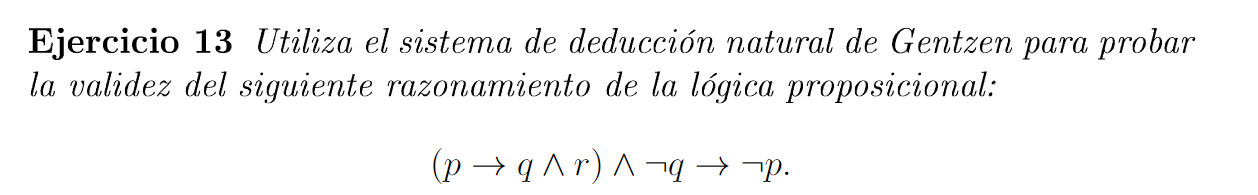

$ \vdash (p \rightarrow (q \wedge r \wedge s)) \rightarrow \neg r \rightarrow \neg p$

In [14]:
def proof[P, Q, R, S]: (P => (Q, (R, S))) => Not[R] => Not[P] = 
    (f: P => (Q, (R, S))) => (nq: Not[R]) => (p: P) =>
        nq(f(p)._2._1 : R)

defined function proof

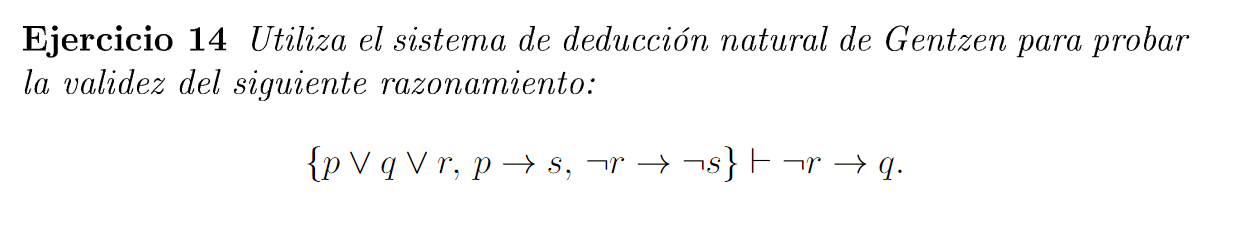

$\{ p\vee q \vee r, p \rightarrow s, \neg r \rightarrow \neg s\} \vdash \neg r \rightarrow q$

In [15]:
def proof[P, Q, R, S](pqr: Either[P, Either[Q, R]], 
                      ps: P => S, 
                      rs: Not[R] => Not[S]): 
                          Not[R] => Q = 
    nr => pqr match {
        case Left(p) => rs(nr)(ps(p)) : Q
        case Right(Left(q)) => q
        case Right(Right(r)) => nr(r)
    }

defined function proof

# DN

$ A \wedge \neg A \vdash B $, sin utilizar $\bot \vdash B$

In [16]:
def proof[A, B](dn: Not[Not[B]] => B): (A, Not[A]) => B = 
    (a: A, na: Not[A]) => 
        dn((nb: Not[B]) => na(a))
    //  na(a)

defined function proof

$ A \rightarrow B \vdash \neg B \rightarrow \neg A $

In [17]:
def proof[A, B]: (A => B) => Not[B] => Not[A] = 
    (f: A => B) => (nb: Not[B]) => 
        (a: A) => nb(f(a))

defined function proof

$ A \rightarrow \neg B \vdash B \rightarrow \neg A $

In [18]:
def proof[A, B]: (A => Not[B]) => B => Not[A] = 
    (f: A => Not[B]) => (b: B) => 
        (a: A) => f(a)(b)

defined function proof

$ \neg A \rightarrow B \vdash \neg B \rightarrow A $

In [19]:
def proof[A, B](dn: Not[Not[A]] => A): (Not[A] => B) => Not[B] => A = 
    (f: Not[A] => B) => (nb: Not[B]) => 
        dn((na: Not[A]) => nb(f(na) : B)) : A

defined function proof

$ \neg A \rightarrow \neg B \vdash B \rightarrow A $

In [20]:
def proof[A, B](dn: Not[Not[A]] => A): (Not[A] => Not[B]) => B => A = 
    (f: Not[A] => Not[B]) => (b: B) => 
        dn((na: Not[A]) => f(na)(b)): A

defined function proof

# Interdefiniciones

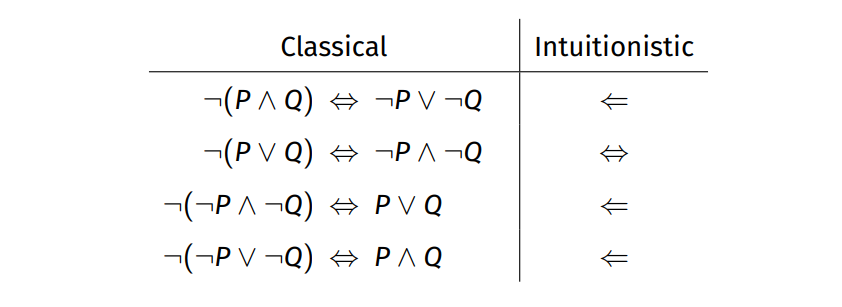

$ A \rightarrow B \leftrightarrow \neg A \vee B $ 

In [21]:
def proof[A, B]: (A => B) => Either[Not[A], B] = 
    (f: A => B) => ???  

defined function proof

In [22]:
def proof[A, B]: Either[Not[A], B] => (A => B) = 
    { 
        case Left(na) => a => na(a)
        case Right(b) => _ => b
    }

defined function proof

#### Extraordinaria 22-23 GII

$ A \wedge B \leftrightarrow \neg (A \rightarrow \neg B) $ 

In [10]:
def proof[P, Q]: (P, Q) => Not[P => Not[Q]] = 
    (p: P, q: Q) => (f: P => Not[Q]) => 
        f(p : P)(q : Q)

defined function proof

In [11]:
def proof[P, Q](lemp: Either[P, Not[P]], lemq: Either[Q, Not[Q]]): Not[P => Not[Q]] => (P, Q) = 
    (n: (P => Q => Nothing) => Nothing) => (lemp, lemq) match {
        case (Left(p), Left(q)) => (p, q)
        case (_, Right(nq)) => n(_ => nq)
        case (Right(np), Left(q)) => (n((p: P) => (_ : Q) => np(p)), q)
    }

defined function proof

#### Extraordinaria 22-23 GII
$ A \wedge B \iff \neg(\neg A \vee \neg B) $

In [4]:
def proof[A, B]: (A, B) => Not[Either[Not[A], Not[B]]] = 
    (a: A, b: B) => {
        case Left(na: Not[A]) => na(a)
        case Right(nb: Not[B]) => nb(b)
    }

defined function proof

In [2]:
def proof[A, B](lemp: Either[A, Not[A]], lemq: Either[B, Not[B]]): Not[Either[Not[A], Not[B]]] => (A, B) = 
    n => (lemp, lemq) match {
        case (Left(a), Left(b)) => (a,b)
        case (Left(a), Right(nb)) => (a, n(Right(nb)))
        case (Right(na), Left(b)) => (n(Left(na)), b)
        case (Right(na), Right(nb)) => (n(Left(na)), n(Right(nb)))
    }

defined function proof

In [3]:
def proof[A, B]: Not[Either[Not[A], Not[B]]] => (A, B) = 
    n => (n(Left(a => ???)), n(Left(a => ???)))

defined function proof

$ A \vee B \iff \neg A \rightarrow B $

In [25]:
def proof[A, B]: Either[A, B] => Not[A] => B = 
    {
        case Left(a) => na => na(a)
        case Right(b) => _ => b
    }

defined function proof

In [26]:
def proof[A, B]: (Not[A] => B) => Either[A, B] = 
    (f: Not[A] => B) => 
        ???

defined function proof

# Varios

$ \neg \neg (p \wedge q) \iff \neg\neg p \wedge \neg\neg q $, from Heyting. intro to intuitionism, 3rd ed., p. 105

In [27]:
def proof[P, Q]: Not[Not[(P, Q)]] => (Not[Not[P]], Not[Not[Q]]) = 
    (nnpq: Not[(P, Q)] => Nothing) => 
        ((np: P => Nothing) => 
             nnpq((t: (P, Q)) => np(t._1) : Nothing), 
         nq => ???)

defined function proof

In [28]:
def proof[P, Q]: (Not[Not[P]], Not[Not[Q]]) => Not[Not[(P, Q)]]  = 
    (nnp: (P => Nothing) => Nothing, 
     nnq: (Q => Nothing) => Nothing) => 
    (npq: ((P, Q)) => Nothing) => 
        //npq((??? : P, ??? : Q))
        nnp((p: P) => 
            nnq((q: Q) => 
                npq((p, q))))

defined function proof

$ \neg \neg (p \vee q) \leftarrow \neg\neg p \vee \neg\neg q $, from Heyting. intro to intuitionism, 3rd ed., p. 105

In [29]:
def proof[P, Q]: Either[Not[Not[P]], Not[Not[Q]]] => Not[Not[Either[P, Q]]] = 
    e => (npq: Either[P, Q] => Nothing) => e match {
        case Left(nnp: ((P => Nothing) => Nothing)) => 
            nnp((p: P) => npq(Left(p)))
        case Right(nnq) => 
            ???
    }

defined function proof